# QPSK Simulation with an IQ Mach–Zehnder Modulator

This notebook extends `simulacao_coerente_qpsk.ipynb`: it retains the coherent-system BER analyses, adds different transmitter and receiver linewidths, and replaces the ideal transmitter with an IQ-MZM based on `Mach_Zehnder_Modulator_DP.m` and `Mach_Zehnder_Modulator_simplificado.m`.

The mode is explicitly set to `iq_mzm`. Other scripts and notebooks continue to use `ideal` as the default for `modulate_optical_signal`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.dsp.transmitter import (
    ElectricalFilterParams,
    IQMZMParams,
    generate_qpsk_symbols,
    modulate_optical_signal,
)
from src.dsp.fiber import fibra_monomodo, FiberParams
from src.dsp.noise_models import generate_correlated_phases, generate_wiener_phase_noise, add_awgn_noise
from src.dsp.receiver import (
    coherent_detection,
    cd_compensation,
    sample_to_symbols,
    demap_qpsk,
)
from src.utils.metrics import calculate_ber, calculate_evm

FIG_DIR = PROJECT_ROOT / 'artifacts' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f'Raiz do projeto: {PROJECT_ROOT}')

Raiz do projeto: D:\gits\PHOTONICS_2026\Codigos\python\pnn_coerente


## 1. System Parameters

The earlier notebook description specified 8 samples per symbol, although its parameter cell used 16. This notebook follows the documented value of 8 SpS. The symbol rate remains 10 GBaud.

In [2]:
NUM_SYMBOLS = 2**14
SPS = 2**3
SYMBOL_RATE = 10e9
FILTER_PARAMS = ElectricalFilterParams(
    tipo='butterworth',
    largura_banda_hz=0.75*SYMBOL_RATE,  # B = Rs = 10 GHz, bandwidth at −3 dB
    ordem=7,
)
WAVELENGTH = 1550e-9
FIBER_PARAMS = FiberParams()
IQ_PARAMS = IQMZMParams(electrical_response=False)
MODULATOR = 'iq_mzm'

print(f'Symbols: {NUM_SYMBOLS}')
print(f'Samples per symbol: {SPS}')
print(f'Symbol rate: {SYMBOL_RATE / 1e9:.1f} GBaud')
print(f'Modulador: {MODULATOR}')
print(f'Vpi I/Q: {IQ_PARAMS.v_pi_i:.2f} V / {IQ_PARAMS.v_pi_q:.2f} V')
print(f'Relative branch phase: {IQ_PARAMS.quadrature_phase_rad / np.pi:.2f} pi rad')

Symbols: 16384
Samples per symbol: 8
Symbol rate: 10.0 GBaud
Modulador: iq_mzm
Vpi I/Q: 3.10 V / 3.25 V
Relative branch phase: -0.50 pi rad


## 2. Quick IQ-Modulation Check

Before link analyses, verify that the IQ-MZM generates the four expected QPSK symbols without noise or electrical filtering. This cell is small and independent of the fiber simulations.

Noise-free check BER: 0
Maximum constellation error: 1.570e-16


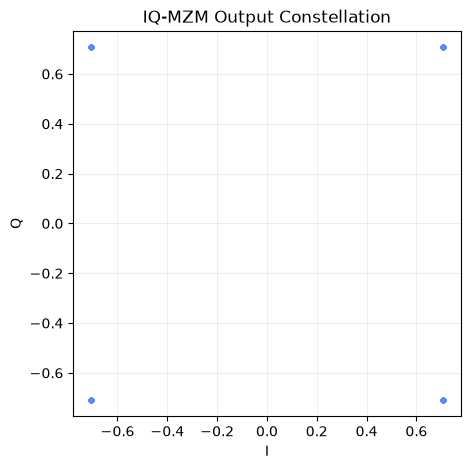

In [3]:
probe_symbols, probe_bits = generate_qpsk_symbols(512, seed=42)
probe_field, probe_t, probe_dt = modulate_optical_signal(
    probe_symbols,
    sps=SPS,
    launch_power_dbm=0.0,
    symbol_rate=SYMBOL_RATE,
    modulator=MODULATOR,
    iq_params=IQ_PARAMS,
)
probe_rx = sample_to_symbols(probe_field, sps=SPS)
probe_rx /= np.sqrt(np.mean(np.abs(probe_rx) ** 2))
probe_bits_rx = demap_qpsk(probe_rx)
probe_ber = calculate_ber(probe_bits, probe_bits_rx)
probe_constellation_error = np.max(np.abs(probe_rx - probe_symbols))

assert probe_ber == 0.0
assert probe_constellation_error < 1e-12
print(f'Noise-free check BER: {probe_ber:.3g}')
print(f'Maximum constellation error: {probe_constellation_error:.3e}')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(probe_rx.real[:200], probe_rx.imag[:200], s=10)
ax.set_xlabel('I')
ax.set_ylabel('Q')
ax.set_title('IQ-MZM Output Constellation')
ax.axis('equal')
ax.grid(True, alpha=0.3)
plt.show()

## 3. Analysis 1: BER vs. Distance

Compare the signal with and without CDC at different launch powers. The transmitter now passes through both IQ sub-MZMs.

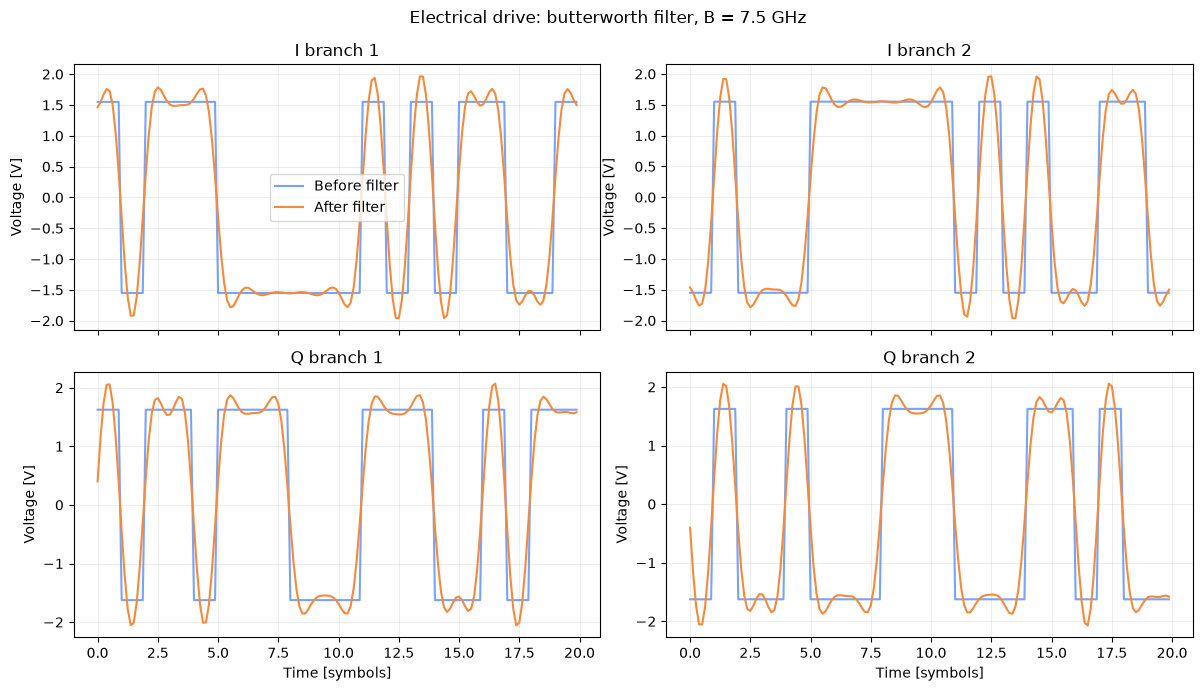

Analysis 1 completed.


In [4]:
distances = np.arange(100, 1300, 100)
powers_dbm = [-10.0, 0.0, 10.0]
snr_ref_db = 16.0
results_a1 = {}

for idx_p, p_dbm in enumerate(powers_dbm):
    ber_no_cdc = []
    ber_with_cdc = []
    evm_with_cdc = []

    for idx_dist, dist in enumerate(distances):
        symbols, bits = generate_qpsk_symbols(NUM_SYMBOLS, seed=42)
        u_tx, t, dt = modulate_optical_signal(
            symbols,
            sps=SPS,
            launch_power_dbm=p_dbm,
            symbol_rate=SYMBOL_RATE,
            modulator=MODULATOR,
            iq_params=IQ_PARAMS,
            filter_params=FILTER_PARAMS,
            plot_filter=(idx_p == 0 and idx_dist == 0),
            n_plot=20,
        )
        steps = max(5, int(dist / 100 * 10))
        u_rx, _, _ = fibra_monomodo(
            t,
            u_tx,
            wavelength=WAVELENGTH,
            t0=1.0 / SYMBOL_RATE,
            length_km=dist,
            regime=1,
            params=FIBER_PARAMS,
            num_steps=steps,
        )
        u_rx_noisy = add_awgn_noise(u_rx, snr_db=snr_ref_db, seed=int(dist))
        r_bb = coherent_detection(u_rx_noisy, phase_lo=np.zeros(len(t)))

        syms_no_cdc = sample_to_symbols(r_bb, sps=SPS)
        ber_no_cdc.append(calculate_ber(bits, demap_qpsk(syms_no_cdc)))

        r_cdc = cd_compensation(
            r_bb,
            dt=dt,
            length_km=dist,
            dispersion_d=FIBER_PARAMS.d_1550,
        )
        syms_cdc = sample_to_symbols(r_cdc, sps=SPS)
        ber_with_cdc.append(calculate_ber(bits, demap_qpsk(syms_cdc)))
        evm_with_cdc.append(calculate_evm(symbols, syms_cdc))

    results_a1[p_dbm] = {
        'ber_no_cdc': ber_no_cdc,
        'ber_with_cdc': ber_with_cdc,
        'evm_with_cdc': evm_with_cdc,
    }

print('Analysis 1 completed.')

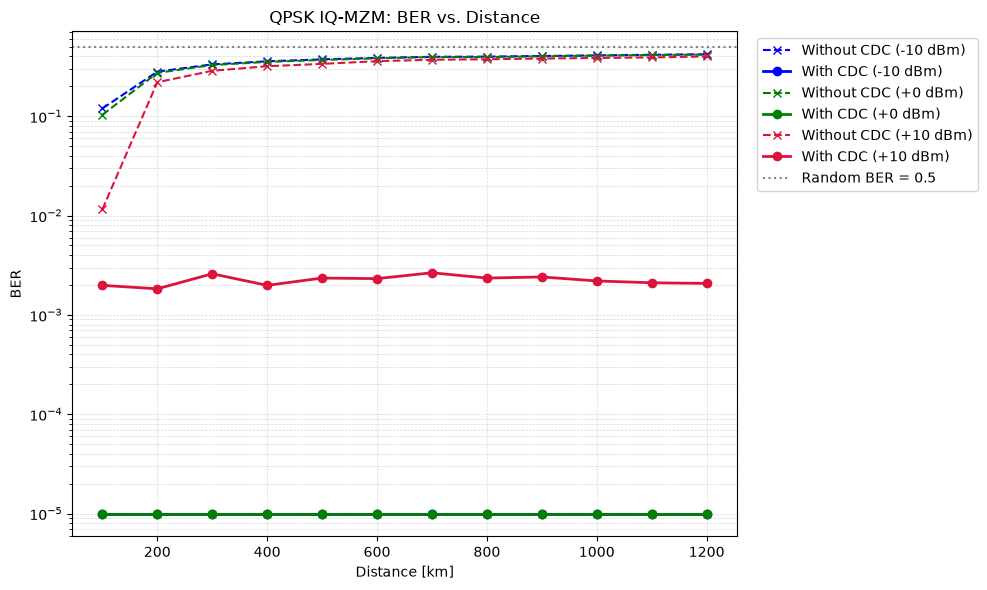

In [5]:
plt.figure(figsize=(10, 6))
colors = {-10.0: 'blue', 0.0: 'green', 10.0: 'crimson'}

for p_dbm, result in results_a1.items():
    color = colors[p_dbm]
    plt.semilogy(
        distances,
        np.maximum(result['ber_no_cdc'], 1e-5),
        '--x',
        color=color,
        label=f'Without CDC ({p_dbm:+.0f} dBm)',
    )
    plt.semilogy(
        distances,
        np.maximum(result['ber_with_cdc'], 1e-5),
        '-o',
        color=color,
        linewidth=2,
        label=f'With CDC ({p_dbm:+.0f} dBm)',
    )

plt.axhline(0.5, color='gray', linestyle=':', label='Random BER = 0.5')
plt.title('QPSK IQ-MZM: BER vs. Distance')
plt.xlabel('Distance [km]')
plt.ylabel('BER')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(FIG_DIR / 'iq_mzm_analise_1_ber_vs_distancia.png', dpi=250)
plt.show()

## 4. Analysis 2: BER vs. Independent Phase Noise

Keep the link at 200 km and vary linewidth for independent lasers, with no phase estimator at the receiver.

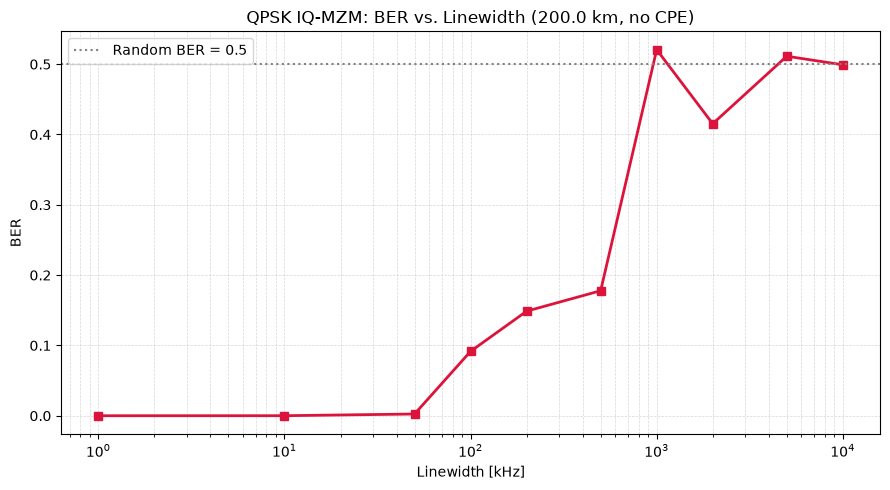

In [6]:
dist_fixed = 200.0
snr_ref_db = 20.0
linewidths_hz_a2 = np.array([0, 10e3, 50e3, 100e3, 200e3, 500e3, 1e6, 2e6, 5e6, 10e6])
symbols_a2, bits_a2 = generate_qpsk_symbols(NUM_SYMBOLS, seed=42)
u_tx_a2, t_a2, dt_a2 = modulate_optical_signal(
    symbols_a2,
    sps=SPS,
    launch_power_dbm=0.0,
    symbol_rate=SYMBOL_RATE,
    modulator=MODULATOR,
    iq_params=IQ_PARAMS,
    filter_params=FILTER_PARAMS,
)
u_rx_a2, _, _ = fibra_monomodo(
    t_a2,
    u_tx_a2,
    wavelength=WAVELENGTH,
    t0=1.0 / SYMBOL_RATE,
    length_km=dist_fixed,
    regime=1,
    params=FIBER_PARAMS,
    num_steps=10,
)
u_rx_a2 = cd_compensation(
    u_rx_a2,
    dt=dt_a2,
    length_km=dist_fixed,
    dispersion_d=FIBER_PARAMS.d_1550,
)
u_rx_a2 = add_awgn_noise(u_rx_a2, snr_db=snr_ref_db, seed=100)

ber_a2 = []
for linewidth in linewidths_hz_a2:
    phi_tx, phi_lo = generate_correlated_phases(
        len(t_a2),
        dt=dt_a2,
        linewidth_hz=linewidth,
        correlation_rho=0.0,
        seed=int(linewidth),
    )
    r_bb = coherent_detection(u_rx_a2 * np.exp(1j * phi_tx), phase_lo=phi_lo)
    rx_symbols = sample_to_symbols(r_bb, sps=SPS)
    ber_a2.append(calculate_ber(bits_a2, demap_qpsk(rx_symbols)))

plt.figure(figsize=(9, 5))
linewidths_khz = np.where(linewidths_hz_a2 == 0, 1.0, linewidths_hz_a2 / 1e3)
plt.semilogx(linewidths_khz, ber_a2, '-s', color='crimson', linewidth=2)
plt.axhline(0.5, color='gray', linestyle=':', label='Random BER = 0.5')
plt.title(f'QPSK IQ-MZM: BER vs. Linewidth ({dist_fixed} km, no CPE)')
plt.xlabel('Linewidth [kHz]')
plt.ylabel('BER')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'iq_mzm_analise_2_ber_vs_phase_noise.png', dpi=250)
plt.show()

## 5. Analysis 3: BER with Different TX and RX Linewidths

Test the 100 ordered pairs among the 10 linewidth values. TX phase is applied to the optical field at the transmitter output and propagates through the link; independent LO phase is applied during coherent detection. The matrix shows BER with transmitter linewidth by row and receiver/LO linewidth by column; the diagonal is omitted.

In [7]:
from pathlib import Path

# Caminho onde as constelações serão salvas (pode ser alterado)
CONSTELLATION_DIR = FIG_DIR / 'constelacoes_a3'
CONSTELLATION_DIR.mkdir(parents=True, exist_ok=True)

# Matriz de decisão: 1 = salvar a constelação, 0 = não salvar.
# Linhas = linewidth do TX, colunas = linewidth do RX/LO.
linewidths_txrx_hz_a3 = linewidths_hz_a2.copy()
num_linewidths_a3 = len(linewidths_txrx_hz_a3)
save_mask_a3 = np.zeros((num_linewidths_a3, num_linewidths_a3), dtype=int)
save_mask_a3[0, 0] = 1                                  # exemplo: ambos sem ruído
eq_pos = np.linspace(0, num_linewidths_a3 - 1, num_linewidths_a3, dtype=int)
save_mask_a3[eq_pos, eq_pos] = 1
#save_mask_a3[num_linewidths_a3 - 1, num_linewidths_a3 - 1] = 1  # exemplo: ambos no maior
# save_mask_a3[:] = 1                                   # para salvar todas

In [8]:
def linewidth_to_filename(linewidth_hz):
    """Rótulo seguro para nome de arquivo (sem espaços)."""
    if linewidth_hz == 0:
        return '0Hz'
    if linewidth_hz >= 1e6:
        return f'{linewidth_hz / 1e6:g}MHz'
    return f'{linewidth_hz / 1e3:g}kHz'


def save_constellation(
    rx_symbols,
    tx_symbols,
    linewidth_tx_hz,
    linewidth_rx_hz,
    correlation_rho,
    save_dir,
    dpi=200,
):
    """Salva o diagrama de constelação com RX (azul) e TX (laranja) sobreposto."""
    rx_symbols = np.asarray(rx_symbols)
    rx_symbols = rx_symbols/np.sqrt(np.mean(np.abs(rx_symbols)**2))
    tx_symbols = np.asarray(tx_symbols)

    fig, ax = plt.subplots(figsize=(6, 6))
    # 1º plot: sinal recebido (círculos azuis preenchidos), fica por baixo
    ax.scatter(
        rx_symbols.real, rx_symbols.imag,
        marker='o', s=12, color='tab:blue', alpha=0.6,
        label='RX', zorder=1,
    )
    # 2º plot: sinal transmitido (X laranja), fica por cima
    ax.scatter(
        tx_symbols.real, tx_symbols.imag,
        marker='x', s=60, linewidths=2, color='orange',
        label='TX', zorder=2,
    )
    ax.axhline(0, color='gray', lw=0.5)
    ax.axvline(0, color='gray', lw=0.5)
    ax.set_aspect('equal', adjustable='datalim')
    ax.set_xlabel('In-phase')
    ax.set_ylabel('Quadrature')
    ax.set_title(
        f'Constellation\nTX: {linewidth_to_filename(linewidth_tx_hz)} | '
        f'RX: {linewidth_to_filename(linewidth_rx_hz)} | ρ = {correlation_rho}'
    )
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')
    fig.tight_layout()

    filename = (
        f'constellation_tx{linewidth_to_filename(linewidth_tx_hz)}'
        f'_rx{linewidth_to_filename(linewidth_rx_hz)}'
        f'_cor{correlation_rho}.png'
    )
    fig.savefig(Path(save_dir) / filename, dpi=dpi)
    plt.close(fig)  # evita acumular figuras abertas no laço

Tested TX/RX combinations: 90


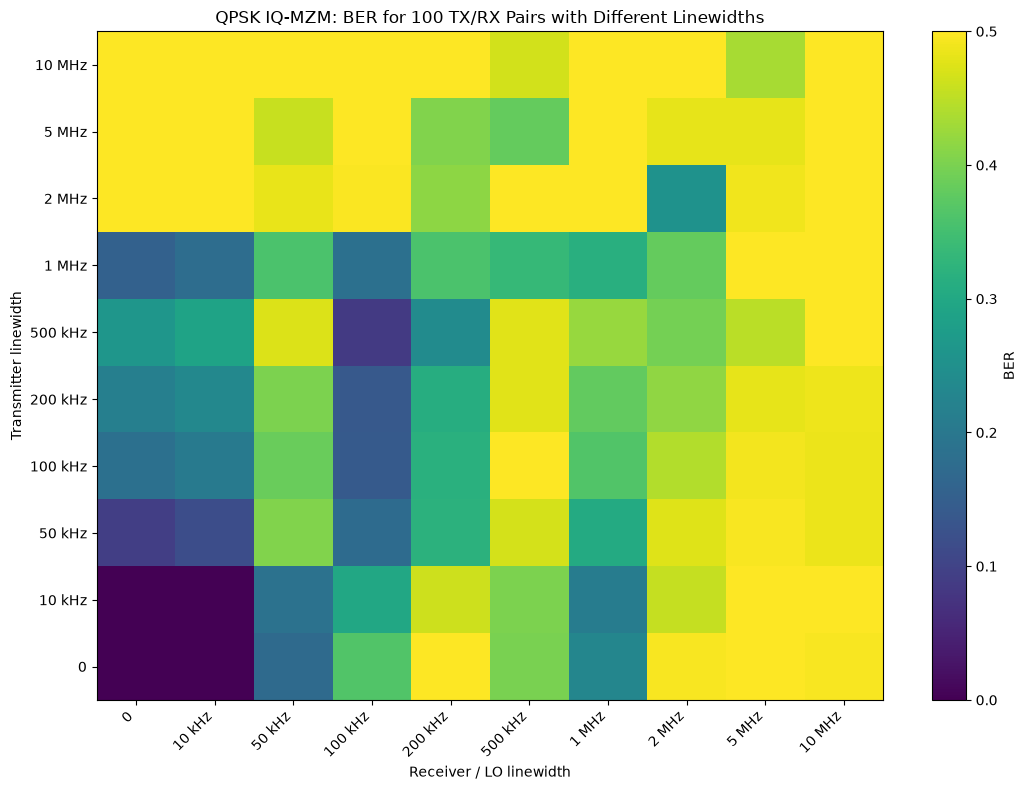

In [9]:
ber_tx_rx_a3 = np.full((num_linewidths_a3, num_linewidths_a3), np.nan)

# Generate an independent realization for each TX and RX linewidth.
# Separate seeds keep TX and LO statistically independent and reproducible.
phase_tx_a3 = [
    generate_wiener_phase_noise(
        len(t_a2), dt_a2, linewidth_hz=float(linewidth), seed=42000 + idx
    )
    for idx, linewidth in enumerate(linewidths_txrx_hz_a3)
]
phase_rx_a3 = [
    generate_wiener_phase_noise(
        len(t_a2), dt_a2, linewidth_hz=float(linewidth), seed=84000 + idx
    )
    for idx, linewidth in enumerate(linewidths_txrx_hz_a3)
]

for idx_tx, linewidth_tx in enumerate(linewidths_txrx_hz_a3):
    # TX laser phase is applied at launch and propagates through the optical link.
    u_tx_with_phase = u_tx_a2 * np.exp(1j * phase_tx_a3[idx_tx])
    u_rx_tx, _, _ = fibra_monomodo(
        t_a2,
        u_tx_with_phase,
        wavelength=WAVELENGTH,
        t0=1.0 / SYMBOL_RATE,
        length_km=dist_fixed,
        regime=1,
        params=FIBER_PARAMS,
        num_steps=10,
    )
    u_rx_tx = add_awgn_noise(u_rx_tx, snr_db=snr_ref_db, seed=100)

    for idx_rx, linewidth_rx in enumerate(linewidths_txrx_hz_a3):
        #if idx_tx == idx_rx:
        #    continue  # Exclude the 10 pairs with equal linewidths.

        r_bb = coherent_detection(
            u_rx_tx,
            phase_lo=phase_rx_a3[idx_rx],
        )
        r_bb = cd_compensation(
        r_bb,
        dt=dt_a2,
        length_km=dist_fixed,
        dispersion_d=FIBER_PARAMS.d_1550,
    )
        rx_symbols = sample_to_symbols(r_bb, sps=SPS)
        ber_tx_rx_a3[idx_tx, idx_rx] = calculate_ber(
            bits_a2, demap_qpsk(rx_symbols)
        )

num_combinations_a3 = np.count_nonzero(~np.eye(num_linewidths_a3, dtype=bool))
print(f'Tested TX/RX combinations: {num_combinations_a3}')

# Categorical labels preserve the zero-linewidth position in the plot.
def format_linewidth_label(linewidth_hz):
    if linewidth_hz == 0:
        return '0'
    if linewidth_hz >= 1e6:
        return f'{linewidth_hz / 1e6:g} MHz'
    return f'{linewidth_hz / 1e3:g} kHz'

linewidth_labels_a3 = [
    format_linewidth_label(value) for value in linewidths_txrx_hz_a3
]
cmap_a3 = plt.get_cmap('viridis').copy()
cmap_a3.set_bad('lightgray')
fig, ax = plt.subplots(figsize=(11, 8))
image = ax.imshow(
    np.ma.masked_invalid(ber_tx_rx_a3),
    origin='lower',
    aspect='auto',
    interpolation='nearest',
    cmap=cmap_a3,
    vmin=0.0,
    vmax=0.5,
)
ax.set_xticks(np.arange(num_linewidths_a3), labels=linewidth_labels_a3, rotation=45, ha='right')
ax.set_yticks(np.arange(num_linewidths_a3), labels=linewidth_labels_a3)
ax.set_xlabel('Receiver / LO linewidth')
ax.set_ylabel('Transmitter linewidth')
ax.set_title('QPSK IQ-MZM: BER for 100 TX/RX Pairs with Different Linewidths')
#for idx in range(num_linewidths_a3):
#    ax.text(idx, idx, 'excluded', ha='center', va='center', fontsize=7, #color='black')
fig.colorbar(image, ax=ax, label='BER')
fig.tight_layout()
plt.savefig(FIG_DIR / 'iq_mzm_analise_3_ber_tx_rx_linewidths.png', dpi=250)
plt.show()


Tested TX/RX combinations: 90


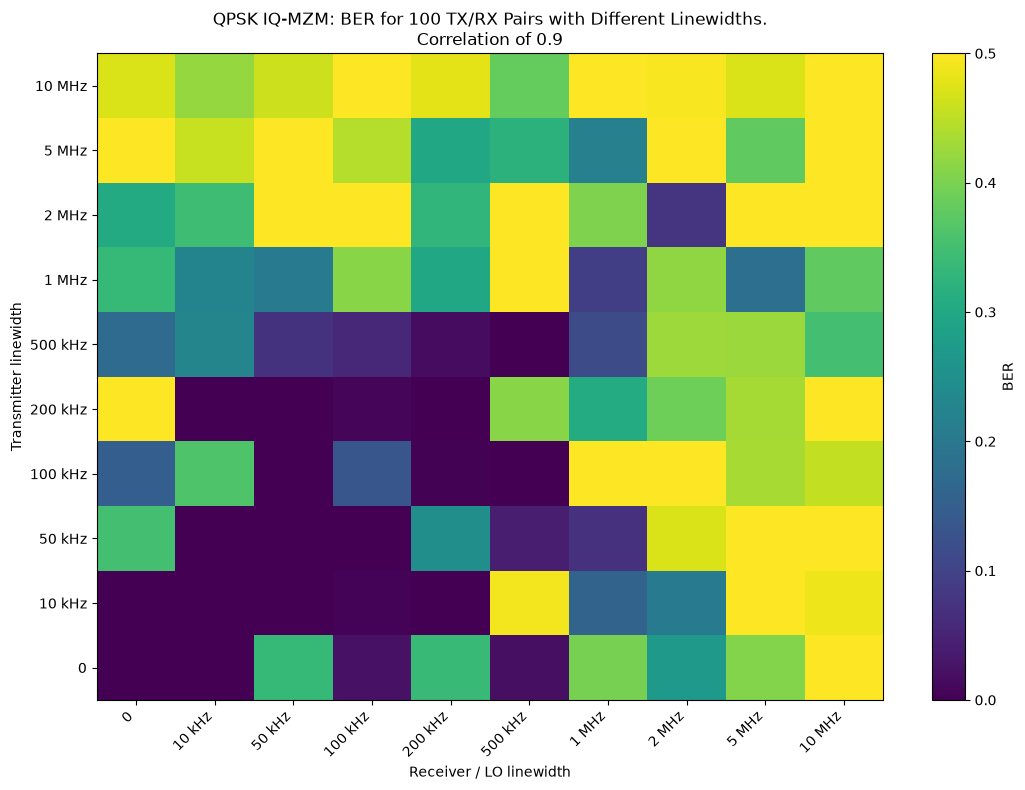

In [10]:
linewidths_txrx_hz_a3 = linewidths_hz_a2.copy()
num_linewidths_a3 = len(linewidths_txrx_hz_a3)
ber_tx_rx_a3 = np.full((num_linewidths_a3, num_linewidths_a3), np.nan)

# Coeficiente de correlação entre TX e LO (0.0 = lasers independentes, 1.0 = self-homodyne)
correlation_rho_a3 = 0.9
s = (len(linewidths_txrx_hz_a3),len(linewidths_txrx_hz_a3),len(t_a2))
phase_tx_a3 = np.zeros(s)
phase_rx_a3 = np.zeros(s)
for idx, linewidth in enumerate(linewidths_txrx_hz_a3):
    for idx2, linewidth2 in enumerate(linewidths_txrx_hz_a3):
        phi_tx, phi_lo = generate_correlated_phases(
            num_samples=len(t_a2),
            dt=dt_a2,
            linewidth_hz=float(linewidth),
            linewidth_lo_hz=float(linewidth2),
            correlation_rho=correlation_rho_a3,
            seed=42000 + idx + idx2,
        )
        phase_tx_a3[idx][idx2][:] = phi_tx
        phase_rx_a3[idx][idx2][:] = phi_lo


for idx_tx, linewidth_tx in enumerate(linewidths_txrx_hz_a3):
    for idx_rx, linewidth_rx in enumerate(linewidths_txrx_hz_a3):
        # TX laser phase is applied at launch and propagates through the optical link.
        u_tx_with_phase = u_tx_a2 * np.exp(1j * phase_tx_a3[idx_tx][idx_rx][:])
        u_rx_tx, _, _ = fibra_monomodo(
            t_a2,
            u_tx_with_phase,
            wavelength=WAVELENGTH,
            t0=1.0 / SYMBOL_RATE,
            length_km=dist_fixed,
            regime=1,
            params=FIBER_PARAMS,
            num_steps=10,
        )
        u_rx_tx = add_awgn_noise(u_rx_tx, snr_db=snr_ref_db, seed=100)

        r_bb = coherent_detection(
            u_rx_tx,
            phase_lo=phase_rx_a3[idx_tx][idx_rx][:],
        )
        r_bb = cd_compensation(
            r_bb,
            dt=dt_a2,
            length_km=dist_fixed,
            dispersion_d=FIBER_PARAMS.d_1550,
        )
        rx_symbols = sample_to_symbols(r_bb, sps=SPS)
        ber_tx_rx_a3[idx_tx, idx_rx] = calculate_ber(
            bits_a2, demap_qpsk(rx_symbols)
        )

        if save_mask_a3[idx_tx, idx_rx] == 1:
            save_constellation(
                rx_symbols=rx_symbols,
                tx_symbols=symbols_a2,   # <- símbolos QPSK transmitidos
                linewidth_tx_hz=linewidth_tx,
                linewidth_rx_hz=linewidth_rx,
                correlation_rho=correlation_rho_a3,
                save_dir=CONSTELLATION_DIR,
            )

num_combinations_a3 = np.count_nonzero(~np.eye(num_linewidths_a3, dtype=bool))
print(f'Tested TX/RX combinations: {num_combinations_a3}')


# Categorical labels preserve the zero-linewidth position in the plot.
def format_linewidth_label(linewidth_hz):
    if linewidth_hz == 0:
        return '0'
    if linewidth_hz >= 1e6:
        return f'{linewidth_hz / 1e6:g} MHz'
    return f'{linewidth_hz / 1e3:g} kHz'


linewidth_labels_a3 = [
    format_linewidth_label(value) for value in linewidths_txrx_hz_a3
]
cmap_a3 = plt.get_cmap('viridis').copy()
cmap_a3.set_bad('lightgray')
fig, ax = plt.subplots(figsize=(11, 8))
image = ax.imshow(
    np.ma.masked_invalid(ber_tx_rx_a3),
    origin='lower',
    aspect='auto',
    interpolation='nearest',
    cmap=cmap_a3,
    vmin=0.0,
    vmax=0.5,
)
ax.set_xticks(np.arange(num_linewidths_a3), labels=linewidth_labels_a3, rotation=45, ha='right')
ax.set_yticks(np.arange(num_linewidths_a3), labels=linewidth_labels_a3)
ax.set_xlabel('Receiver / LO linewidth')
ax.set_ylabel('Transmitter linewidth')
ax.set_title(f'QPSK IQ-MZM: BER for 100 TX/RX Pairs with Different Linewidths.\nCorrelation of {correlation_rho_a3}')
#for idx in range(num_linewidths_a3):
#    ax.text(idx, idx, 'excluded', ha='center', va='center', fontsize=7, #color='black')
fig.colorbar(image, ax=ax, label='BER')
fig.tight_layout()
plt.savefig(FIG_DIR / f'iq_mzm_analise_3_ber_tx_rx_linewidths_cor{correlation_rho_a3}.png', dpi=250)
plt.show()


## 6. Analysis 4: Phase Correlation Between Transmitter and LO

Compare independent lasers with phase-correlated sources while keeping the remaining parameters fixed.

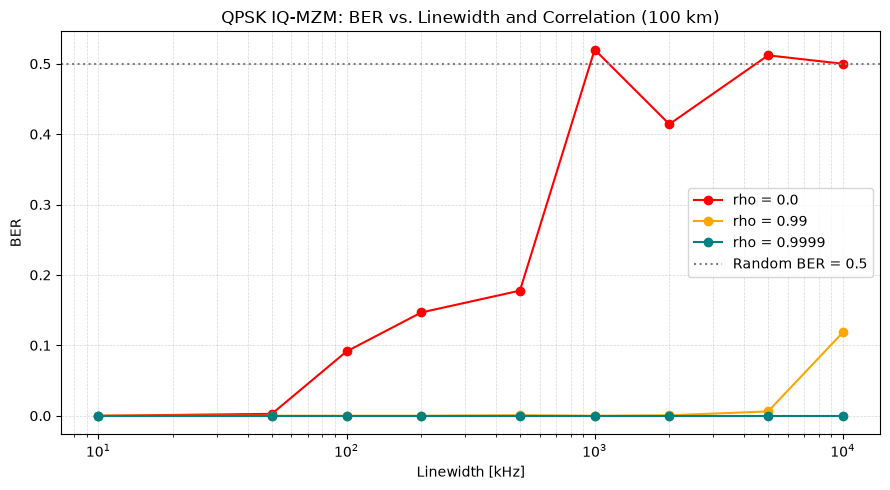

In [11]:
linewidths_hz_a4 = np.array([10e3, 50e3, 100e3, 200e3, 500e3, 1e6, 2e6, 5e6, 10e6])
correlations = [0.0, 0.99, 0.9999]
results_a4 = {}

symbols_a4, bits_a4 = generate_qpsk_symbols(NUM_SYMBOLS, seed=42)
u_tx_a4, t_a4, dt_a4 = modulate_optical_signal(
    symbols_a4,
    sps=SPS,
    launch_power_dbm=0.0,
    symbol_rate=SYMBOL_RATE,
    modulator=MODULATOR,
    iq_params=IQ_PARAMS,
    filter_params=FILTER_PARAMS,
)
u_rx_a4, _, _ = fibra_monomodo(
    t_a4,
    u_tx_a4,
    wavelength=WAVELENGTH,
    t0=1.0 / SYMBOL_RATE,
    length_km=200.0,
    regime=1,
    params=FIBER_PARAMS,
    num_steps=10,
)
u_rx_a4 = cd_compensation(
    u_rx_a4,
    dt=dt_a4,
    length_km=200.0,
    dispersion_d=FIBER_PARAMS.d_1550,
)
u_rx_a4 = add_awgn_noise(u_rx_a4, snr_db=20.0, seed=200)

for rho in correlations:
    ber_values = []
    for linewidth in linewidths_hz_a4:
        phi_tx, phi_lo = generate_correlated_phases(
            len(t_a4),
            dt=dt_a4,
            linewidth_hz=linewidth,
            correlation_rho=rho,
            seed=int(linewidth + rho * 1e6),
        )
        r_bb = coherent_detection(u_rx_a4 * np.exp(1j * phi_tx), phase_lo=phi_lo)
        rx_symbols = sample_to_symbols(r_bb, sps=SPS)
        ber_values.append(calculate_ber(bits_a4, demap_qpsk(rx_symbols)))
    results_a4[rho] = ber_values

plt.figure(figsize=(9, 5))
for rho, color in zip(correlations, ['red', 'orange', 'teal']):
    plt.semilogx(
        linewidths_hz_a4 / 1e3,
        results_a4[rho],
        '-o',
        color=color,
        label=f'rho = {rho}',
    )
plt.axhline(0.5, color='gray', linestyle=':', label='Random BER = 0.5')
plt.title('QPSK IQ-MZM: BER vs. Linewidth and Correlation (100 km)')
plt.xlabel('Linewidth [kHz]')
plt.ylabel('BER')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'iq_mzm_analise_4_ber_vs_correlacao.png', dpi=250)
plt.show()

## Notes on the Model

- `ideal` remains the API default. Cells in this notebook explicitly select `iq_mzm`.
- The IQ-MZM uses two dual-drive push-pull sub-MZMs and the quadrature phase combination from the DP file. All four BER analyses use a seventh-order Gaussian electrical filter with B = Rs = 10 GHz. Distributed electrode response remains disabled; cell 5 retains an unfiltered reference. Analysis 3 tests 90 TX/RX linewidth pairs with independent phases.
- BER analyses inherit the previous notebook's model: specified AWGN SNR, ideal timing, and no amplifiers/ASE. These curves compare model scenarios and are not an experimental link budget.